> **Save your own copy first.** Unless this notebook is already in your own Google Drive, Colab does not keep your changes. Go to **File → Save a copy in Drive** and work in the copy that opens in a new tab. You find it later in Google Drive, in *Colab Notebooks*.

![Cultural Data Analysis · Week 3: Structured Data and Machine Learning](https://goto4711.github.io/cda-teaching-tools/assets/notebooks/week3-banner.png)

*Workshop notebook* · Code-along: [goto4711.github.io/cda-teaching-tools/code-along/week3](https://goto4711.github.io/cda-teaching-tools/code-along/week3/) · Tools: [how a computer sees an image](https://goto4711.github.io/cda-teaching-tools/tools/images/), [neural network training](https://goto4711.github.io/cda-teaching-tools/tools/neural-net/)

---

> **Important:** Please run the cell below to set up the environment.
>
> **To submit:** Run the whole notebook, complete every cell marked `#Complete cell`, and hand in the HTML file that the last cell makes. Sections and cells marked *optional* you can skip.

In [1]:
#Keep cell
# Local version (VS Code on a Mac, Python 3.11): uses Python itself instead of !wget and !pip,
# so it works without wget and installs into the same Python the notebook runs on
import os, sys, subprocess, urllib.request

def pip_install(package):
    cmd = [sys.executable, '-m', 'pip', 'install', '-q', package]
    if subprocess.run(cmd).returncode != 0:
        # Homebrew's Python refuses plain pip installs ("externally managed"); install for this user instead
        subprocess.run(cmd + ['--user', '--break-system-packages'], check=True)

try:
    import learntools.core
except ImportError:
    pip_install('git+https://github.com/goto4711/learntools.git')
    import learntools.core
from learntools.core import binder
binder.bind(globals())

# palettable is needed by CDAIML.py (colours of the neural-network drawing)
try:
    import palettable
except ImportError:
    pip_install('palettable')
    import palettable

downloads = {
    'ml_workshop_tests.py': 'https://raw.githubusercontent.com/goto4711/cdai/refs/heads/main/ml_workshop_tests.py',
    '114_congress.csv':     'https://raw.githubusercontent.com/goto4711/cdai/main/114_congress.csv',
    'spotify-dataset.csv':  'https://raw.githubusercontent.com/goto4711/cdai/refs/heads/main/spotify-dataset.csv',
    'CDAIML.py':            'https://raw.githubusercontent.com/goto4711/cdai/refs/heads/main/CDAIML.py',
}
for file_name, url in downloads.items():
    if not os.path.exists(file_name):
        print('Downloading', file_name)
        urllib.request.urlretrieve(url, file_name)

from ml_workshop_tests import *
from CDAIML import display_youtube

In today's workshop, we work with two real-life datasets: votes in the US Senate and songs on Spotify. As in the lecture, we first let a machine find groups by itself (unsupervised) and then let it learn from labels (supervised).

> **Goals** · By the end of this workshop, you can
> 1. clean a small dataset and cluster it with k-means;
> 2. compare the clusters with what we already know: the parties;
> 3. predict danceability with a decision tree and a random forest;
> 4. say who decided what along the way: the data, the number of clusters, the labels.

Run the cell below to load the standard libraries.

In [2]:
#Keep cell

import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

---

## Unsupervised Machine Learning with Clustering

In the first part, we dig deeper into digital methodologies and data exploration using a particular method called clustering, which is closely related to the understanding of political and social communities. We rely on our trusted k-means clustering to explore political voting behaviour.

As a reminder, k-means tries to develop clusters by
1. initialising a pre-defined number (k) of randomly chosen centroids in the feature space. Centroids are simply the centre points of clusters.
1. The algorithm assigns each observation to the cluster with the closest centroid.
1. Based on how balanced this assignment is, the centroids are recalculated and steps 1 and 2 are repeated until the algorithm balances out.

We will use k-means to understand voting behaviour in the US Senate. We chose a period some years ago, when the Senate was less partisan, as we would like to investigate voting behaviour that crosses party lines. The data is a subset of the data from https://web.archive.org/web/2023/https://www.dataquest.io/blog/k-means-clustering-us-senators/.

Please, run the cell below to create the `congress_114` dataframe, which contains the voting behaviour of the 114th US Senate. According to Wikipedia (https://en.wikipedia.org/wiki/114th_United_States_Congress), the 114th Congress met in Washington, D.C. from 3 January 2015 to 3 January 2017, during the final two years of Barack Obama's presidency.

The 2014 elections gave the Republicans control of the Senate and control of both houses of Congress for the first time since the 109th Congress. With 247 seats in the House of Representatives and 54 seats in the Senate, this Congress began with the largest Republican majority since the 71st Congress of 1929-1931. There are 24 Democrats, 1 Independent and 33 Republicans in our dataset (one of the Democrats did not vote at all, as we will see). As said, this does not represent the full 114th Congress but a sample.

Run the cell below.

In [3]:
#Keep cell

congress_114 = pd.read_csv("114_congress.csv")

### Data Preparation

To warm up, please check the first five entries of the dataset. It contains the name of a particular senator, their party and home state as well as for each bill whether the senator voted for a bill (1) or against it (0). Check out the first 5 rows of `congress_114` with `head()`.

In [4]:
congress_114.head(5)

,index,name,party,state,bill-1,bill-4,bill-5,bill-6,bill-7,bill-8,bill-9,bill-10,bill-20,bill-26,bill-32,bill-38,bill-39,bill-44,bill-47
0,0,Alexander,R,TN,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1,Ayotte,R,NH,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,2,Baldwin,D,WI,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
3,3,Barrasso,R,WY,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4,4,Bennet,D,CO,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


> **Hint:** Run the next cell to get a hint and finally the solution. You know these cells by now, and we will not introduce them anymore.

In [5]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q0.hint()
#q0.solution()

<IPython.core.display.Javascript object>

<span style="color:#3366cc">Hint:</span> Use the .head() method to display the first few rows of a DataFrame. This helps you understand the structure and content of your data. Try: dataframe_name.head(n) where n is the number of rows to display.

In real-life datasets, you find many missing values, shown as NaN in Python: votes never cast or never recorded. There are many strategies to deal with them. Here we use the brute-force one and simply remove the records.

First check how many records have missing values. Run `congress_114[congress_114.isnull().any(axis=1)]`. `isnull()` checks for NaN entries and `any(axis=1)` applies this to all columns.

In [6]:
congress_114[congress_114.isnull().any(axis=1)].isnull()

,index,name,party,state,bill-1,bill-4,bill-5,bill-6,bill-7,bill-8,bill-9,bill-10,bill-20,bill-26,bill-32,bill-38,bill-39,bill-44,bill-47
57,False,False,False,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


That's only one record missing, and senator 'Markey' has not voted at all. This makes us confident that we can just delete them ...

Remove the record. The easiest is to simply remove all the records with NaN values. Pandas has a function for that called `dropna()`. Apply it to `congress_114` and assign the result back to `congress_114`.

In [9]:
congress_114 = congress_114.dropna()

In [11]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q2.check()
#q2.hint()
#q2.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

Now check how many Democrats, Republicans and Independents are in `congress_114`. Type in `congress_114.iloc[:,2].value_counts()` to select column 3 ('party') with iloc and apply `value_counts()` (https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.value_counts.html).

In [13]:
congress_114.iloc[:,2].value_counts()

party
R     33
D     23
I      1
Name: count, dtype: int64

> **Background: a first overview of the Senate data** (optional reading)
>
> Real-life social and cultural datasets are vast and unorganised, and they often lack the quality to be processed easily. In reality, you will spend most of your time on such data challenges.
>
> Two commands give a quick overview of a new dataframe. `congress_114.dtypes` shows the type of each column. The bills are `float` (numbers with decimals), because a column with missing values (NaN) cannot be an integer column in Pandas; after `dropna()`, you could turn them into integers with `congress_114[bill_cols] = congress_114[bill_cols].astype(int)`. Text columns such as the names appear as `object` (or `str` in newer versions of Pandas).
>
> `congress_114.describe()` calculates statistics for all numeric columns. Votes of 1 and 0 have no real average, but the statistics still tell us about the vote across the Senate. Bill 10 got all the votes: its mean is 1 and its standard deviation 0. Bill 9 was very divided: its mean is about 0.58, with a standard deviation of 0.5. How can you see this in the quantiles at the bottom of the output?

For the clustering, we only need the votes. The bills are the only columns with numbers (they are `float`), so we can select them with the Pandas function `select_dtypes(['float'])`. Run:

```
bill_cols = list(congress_114.select_dtypes(['float']).columns)
bill_cols
```

In [15]:
bills_cols = list(congress_114.select_dtypes(['float']).columns)
bills_cols

['bill-1',
 'bill-4',
 'bill-5',
 'bill-6',
 'bill-7',
 'bill-8',
 'bill-9',
 'bill-10',
 'bill-20',
 'bill-26',
 'bill-32',
 'bill-38',
 'bill-39',
 'bill-44',
 'bill-47']

### Clustering with k-means

Let's practice clustering again with k-means. In order to find a good starting point for k, we can use our own knowledge about how the US Senate is structured. We would like to investigate voting clusters, and we know that the US Senate is dominated by 2 major parties. So, it seems like a good idea to start with two clusters (k = 2), as we can assume that there should be two major party-based voting clusters. Please, assign `k = 2`.

Run the cell below.

In [16]:
#Keep cell

k = 2

Next, we need to understand what we would like to cluster and choose the relevant features as inputs into the k-means algorithm. If you look back into your earlier explorations of the dataset, you can see that the first 4 columns do not contain voting behaviour. They have the name, state, etc. of the various senators. The voting behaviour can be found in columns 5 to 19. Use either the column indexes or `bill_cols` to create a new dataframe `congress_114_voting`, which only contains the voting behaviour.  Also, print out the first couple of rows of `congress_114_voting`.

In [18]:
congress_114_voting = congress_114.loc[:, bills_cols]
congress_114_voting.head()

,bill-1,bill-4,bill-5,bill-6,bill-7,bill-8,bill-9,bill-10,bill-20,bill-26,bill-32,bill-38,bill-39,bill-44,bill-47
0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0
3,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [17]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q3.hint()
#q3.solution()

<IPython.core.display.Javascript object>

<span style="color:#3366cc">Hint:</span> Create a subset of the DataFrame containing only the voting columns (bill_cols). Use .loc with column indexing: df.loc[:, column_list] selects all rows and specified columns. Then use .head() to display the first few rows of this subset.

> **Read more:** Great, we are ready to cluster the votes. Check out the details of k-means in the `sklearn` documentation: https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html

Its main arguments are the dataset to cluster and the number of clusters. We can leave all the other inputs at their defaults.

First `import KMeans` from `sklearn.cluster` by running the cell below.

In [19]:
#Keep cell

from sklearn.cluster import KMeans

Now, run `KMeans` and fit it with `n_clusters = k`. Check the documentation and you will find how to do it. We fix `random_state=4711` so that your results match the ones in this notebook. Change the number to see how much the results vary.
```
kmeans = KMeans(n_clusters = k, random_state=4711)
kmeans.fit(congress_114_voting)
```

In [20]:
kmeans = KMeans(n_clusters = k, random_state=4711)
kmeans.fit(congress_114_voting)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",4711
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 15)"

This should not have taken long, as the dataset is very small.

K-means is a standard example of *unsupervised* machine learning: we do not tell the computer in advance which results we expect. The cluster assignments are stored as a one-dimensional NumPy array in `kmeans.labels_`. Here is a look at the first five. Run the cell below.

In [21]:
#Keep cell

kmeans.labels_[:5]

array([1, 1, 0, 1, 0], dtype=int32)

This means the first 5 senators belong to these clusters with the count starting at 0.

Ok, so now that we have run our machine-learning algorithms, what do we do with the results? A good first step for k-means and other clustering algorithms is to check out the size of the clusters. Who do you expect to belong to each cluster?

Use `np.bincount` with `kmeans.labels_`, please, and run `np.bincount(kmeans.labels_)`.

In [22]:
np.bincount(kmeans.labels_)

array([22, 35])

> **Background: inside the k-means model** (optional reading)
>
> After `fit()`, the model `kmeans` stores its results in attributes that end with an underscore (https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html):
> - `kmeans.labels_`: the cluster of each senator, counting from 0;
> - `kmeans.cluster_centers_`: the centre of each cluster, one row per cluster and one column per bill;
> - `kmeans.n_iter_`: the number of rounds k-means needed until the centres stopped moving. For our small dataset, it converges in a few rounds.
>
> A first step with any clustering is to check the size of the clusters, as `np.bincount` does: it counts how often each number appears. Who do you expect in each cluster?

These numbers are already close to the number of seats each party has (33 Republicans, 23 Democrats and 1 Independent), which suggests that the two clusters largely follow party lines. Let's check this.

Create a new dataframe `congress_114_result`, which contains the first 4 columns of `congress_114` as well as the cluster assignments for each senator by k-means. Take a moment to reflect on what we gain from such a new dataframe.

Type in:
```
congress_114_result = congress_114.iloc[:, :4].copy()
congress_114_result["cluster"] = pd.Series(kmeans.labels_)
```
With `:4`, we select the first four columns - the non-bill columns. With `copy()`, we make a copy to keep the original dataframe so that we do not overwrite the old one.

In [23]:
congress_114_result = congress_114.iloc[:, :4].copy()
congress_114_result["cluster"] = pd.Series(kmeans.labels_)

Because we like it tidy, we give the columns of `congress_114_result` new readable names. We can do this by assigning the columns directly to a list of names: `congress_114_result.columns = ['index','name','party', 'state', 'cluster']`.

In [24]:
congress_114_result.columns = ['index','name','party', 'state', 'cluster']

Let's take a look at the composition of `congress_114_result` and print out the whole dataframe. What do you see?

In [25]:
print(congress_114_result)

    index           name    party    state  cluster
0       0     Alexander        R       TN         1
1       1        Ayotte        R       NH         1
2       2       Baldwin        D       WI         0
3       3      Barrasso        R       WY         1
4       4        Bennet        D       CO         0
5       5    Blumenthal        D       CT         0
6       6         Blunt        R       MO         1
7       7        Booker        D       NJ         0
8       8       Boozman        R       AR         1
9       9         Boxer        D       CA         0
10     10         Brown        D       OH         0
11     11          Burr        R       NC         1
12     12      Cantwell        D       WA         0
13     13        Capito        R       WV         1
14     14        Cardin        D       MD         0
15     15        Carper        D       DE         0
16     16         Casey        D       PA         0
17     17       Cassidy        R       LA         1
18     18   

Finally, let's take a look at the composition of our 2 clusters.

In this case, we want to count how often a Democrat appears in cluster 0 or how often in cluster 1; similarly, how often is a Republican part of either cluster 0 or 1. Please note that there are also Independent senators.

In order to compare party and cluster features, use `pd.crosstab`: https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html. With the crosstab function, we can count the frequency of the combination of two columns. Simply run: `pd.crosstab(congress_114_result['party'], congress_114_result['cluster'])`.

In [27]:
pd.crosstab(congress_114_result['party'],congress_114_result['cluster'])

cluster,0,1
party,,
D,21,2
I,1,0
R,0,33


Take a minute to interpret the results. Which party is more coherent in its voting behaviour? Can you identify the outliers by looking through the result dataframe?

`k = 2` seems to have been a fairly good choice for k-means, as there is a lot of overlap between parties and voting clusters.

Let's try `k = 5` next to get more diversified results with 5 clusters.

Run the cell below.

> **Who decided?** The machine found the clusters, but people decided almost everything before that: which votes were recorded and which 15 bills are in the dataset, that a senator who did not vote is removed, that two senators are similar when they vote alike, and that there are k = 2 groups. The parties are not in the data the machine saw, yet we use them to judge the result.

In [28]:
#Keep cell

k = 5

Fit k-means with the new `k`. Assign it to `kmeans_5`. Check out the earlier code for fitting k-means with `k=2`. Simply copy it and run the next cell.

In [35]:
kmeans_5 = KMeans(n_clusters = k, random_state=4711)
kmeans_5.fit(congress_114_voting)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",4711
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 15)"

As we already have a `congress_114_result` dataframe, we just need to create a new column with the new cluster assignments. Create a new column `cluster_5` in congress_114_result using the result from `kmeans_5`. The column should be filled with `np.array(kmeans_5.labels_)`. Note we use the array now to fill the column. Earlier we used `pd.Series`. There are many different ways of doing this.

In [36]:
congress_114_result['cluster_5'] = np.array(kmeans_5.labels_)

In [37]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q4.check()
q4.hint()
#q4.solution() 

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

<IPython.core.display.Javascript object>

<span style="color:#3366cc">Hint:</span> Add the cluster labels from your KMeans model as a new column to the DataFrame. KMeans labels are accessed via .labels_ attribute. Convert to numpy array for consistency: df['new_column'] = np.array(model.labels_)

Now, let's compare voting behaviour and parties again with `crosstab`. Can you change the earlier cell to compare  `cluster_5` and `party` in `congress_114_result`?

In [38]:
pd.crosstab(congress_114_result['party'], congress_114_result['cluster_5'])

cluster_5,0,1,2,3,4
party,,,,,
D,18,0,0,2,3
I,1,0,0,0,0
R,0,31,2,0,0


In [ ]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q5.hint()
#q5.solution()

There is at least one strange outlier in the clusters with regard to voting behaviour of particular Republicans. Let's investigate those Republicans who appear not to vote with the rest of their party or with the Democrats.

The cluster number will change depending on the result of your k-means. So, anything between 0 and 4. You get this number from the table you have just printed out. Use it to filter `congress_114_result` and retrieve the names and states of the senators. So, for instance, in my current run the two Republicans were in cluster 2. So, I run:
```
clusters_of_interest = [2]
congress_114_result.loc[congress_114_result['cluster_5'].isin(clusters_of_interest), ['name', 'state']]
```
`isin()` is a function to check whether something is part of a list. You might have to replace 2 in `clusters_of_interest = [2]` with your cluster number.

In [39]:
clusters_of_interest = [2]
congress_114_result.loc[congress_114_result['cluster_5'].isin(clusters_of_interest), ['name', 'state']]

,name,state
1,Ayotte,NH
20,Collins,ME


### Visualisation

Finally, we want to also visualise the cluster assignment to present how senators are close to each other using a 2-dimensional coordinate system.

> **Background: PCA** (optional reading)
>
> Each senator is described by 15 votes, so the senators live in a feature space with 15 dimensions, which we cannot draw. *Principal component analysis* (PCA, https://en.wikipedia.org/wiki/Principal_component_analysis) creates two new columns, the *principal components*, that keep as much of the differences between the senators as possible. We can then draw them on a page.
>
> Read such a plot with care. The axes have no simple meaning: each component mixes all 15 votes. Senators who are close in the plot voted similarly, but two dimensions cannot show all differences, so some senators may look closer than they are. Go online or ask Gemini how to interpret PCA plots with two dimensions: there are some common pitfalls.

Create a simple visualisation that maps the 5 clusters in 2 dimensions and colour the points that represent the senators according to their 5 k-means clusters.

You need the principal component analysis (PCA) trick to map the bill dimensions (columns) of `congress_114_voting` to 2 dimensions. It is explained here: https://www.datacamp.com/community/tutorials/principal-component-analysis-in-python.

First, load PCA from sklearn with `from sklearn.decomposition import PCA`.

In [40]:
from sklearn.decomposition import PCA

Next, apply a PCA with two components.

Then, create a new dataframe `principal_df` with the results of this analysis and name the two columns `PC_1` and `PC_2`.

Finally, add the columns `name`, `party`, `cluster` and `cluster_5` to `principal_df`. Run:

```
pca = PCA(n_components=2)

principal_components = pca.fit_transform(congress_114_voting)

principal_df = pd.DataFrame(data = principal_components, columns = ['PC_1', 'PC_2'])

principal_df['name'] = congress_114_result.name
principal_df['party'] = congress_114_result.party
principal_df['cluster'] = congress_114_result.cluster
principal_df['cluster_5'] = congress_114_result.cluster_5
```

In [41]:
pca = PCA(n_components=2)

principal_components = pca.fit_transform(congress_114_voting)

principal_df = pd.DataFrame(data= principal_components, columns= ['PC_1', 'PC_2'])

principal_df['name'] = congress_114_result.name
principal_df['party'] = congress_114_result.party
principal_df['cluster'] = congress_114_result.cluster
principal_df['cluster_5'] = congress_114_result.cluster_5

Run the code below to visualise. Do you understand what it is doing?

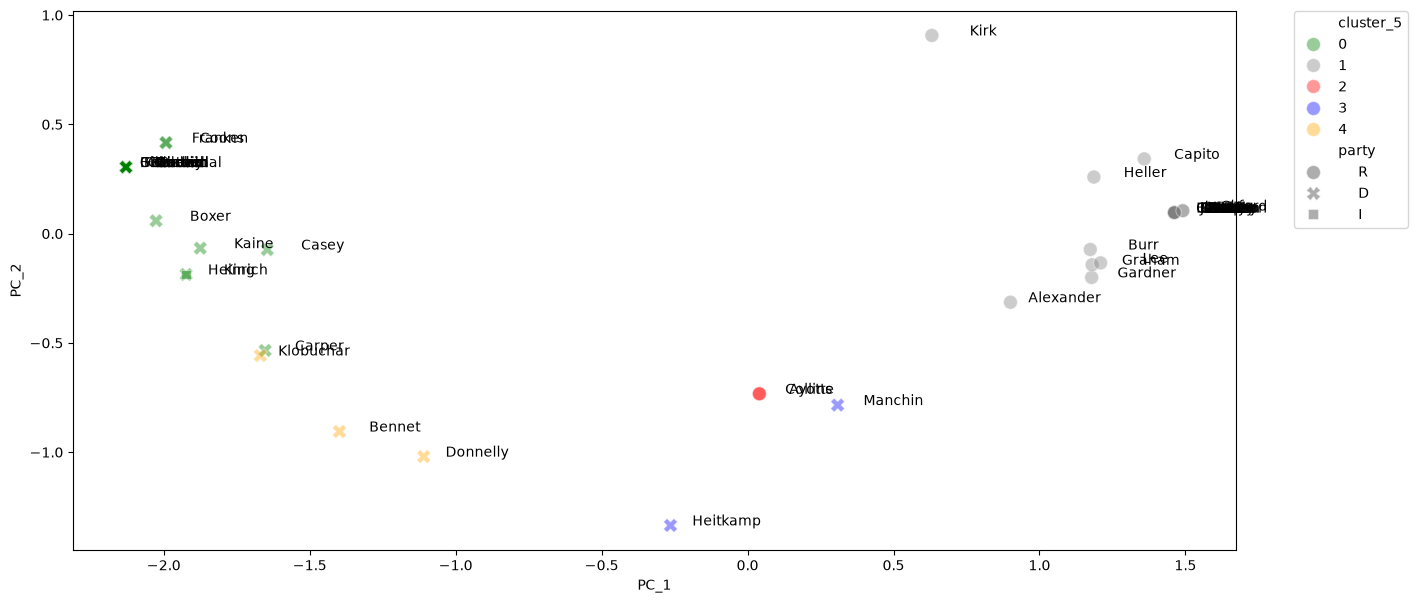

In [42]:
#Keep cell
#based on https://web.archive.org/web/2023/https://honingds.com/blog/seaborn-scatterplot/

import seaborn as sns
plt.figure(figsize=(15,7))

sns.scatterplot(data = principal_df, x='PC_1', y='PC_2', hue='cluster_5',
                style='party', s=100, palette=['green','grey','red','blue','orange'], alpha=.40)

plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
def label_point(x, y, val, ax):
    a = pd.concat({'x': x, 'y': y, 'val': val}, axis=1)
    for i, point in a.iterrows():
        ax.text(point['x']+.02, point['y'], str(point['val']))

label_point(principal_df.PC_1, principal_df.PC_2, principal_df.name, plt.gca())


Take some time now and investigate which senators the outliers are by researching them online. Wikipedia is enough. Can you understand why they are clusters by themselves?

### Determine the optimal number of parties in the Senate according to k-means

So what would be the optimal number of parties in the Senate? In terms of k-means, we need to determine the optimal `k`. There are quite a few methods to estimate `k`. Among the best known ones is the elbow method that is based on visualising trials with several k's: https://pythonprogramminglanguage.com/kmeans-elbow-method/.

The elbow method is a useful graphical tool to estimate the optimal number of clusters `k` for a given task. Intuitively, we can say that, if `k` increases, the within-cluster 'Sum of Squared Errors' (SSE; also called 'distortion') will decrease. SSE is the sum of the squared differences between each observation and its group's mean: https://hlab.stanford.edu/brian/error_sum_of_squares.html.

The idea behind the elbow method is to identify the value of `k` where the distortion stops decreasing rapidly, which will become clearer if we plot the distortion for different values of `k`.

To perform the elbow method, we need to run several k-means, increment `k` with each iteration up to `k = 9` (the loop stops before `max_k = 10`) - and record the SSE-score in a list called sse. Then, map the SSE for each iteration to find the point where the curve bends, the elbow. This will be the best `k`.

You could try this yourself, ask Gemini, or simply run the cells below. Don't forget to try and understand the code. You should recognise most of its components?

In [43]:
#Keep cell

max_k = 10
sse = []

for k in range(1, max_k):
    kmeans_ = KMeans(n_clusters = k, random_state=4711)
    kmeans_.fit(congress_114_voting)
    sse.append(kmeans_.inertia_)

Run the code below to visualise the elbow ...

<Axes: xlabel='Number of Clusters', ylabel='SSE'>

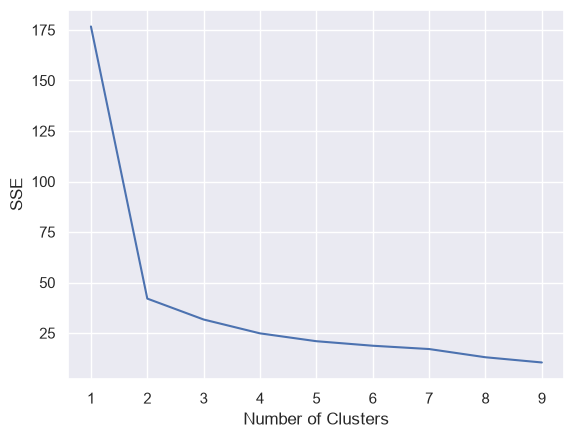

In [44]:
#Keep cell
sns.set(style='darkgrid')

elbow_df  = pd.DataFrame(list(zip(range(1, max_k), sse)),
              columns = ['Number of Clusters', 'SSE'])


sns.lineplot(x = 'Number of Clusters', y = 'SSE', data = elbow_df)

As you can see 2 is already the best answer ...

You can now continue playing with different k values if you want.

> **Read more:** Before we move on, please finally consider https://stats.stackexchange.com/questions/133656/how-to-understand-the-drawbacks-of-k-means.

> **Remember:** The discussion describes that, while clustering (and other machine-learning algorithms) can produce very persuasive results, these do not come for free. There is no free lunch. The results always depend on the assumptions we add like the number of clusters in k-means but also how we describe the vote in the US Congress, how we measure somebody's influence, etc. This is the famous 'No Free Lunch Theorem' in machine learning: https://en.wikipedia.org/wiki/No_free_lunch_theorem.

The theorem also applies to supervised machine learning, which we will practice again for the rest of the workshop.

---

## Supervised Machine Learning

In the lecture, we explored how neural networks can be used to predict danceability. However, when working with structured, tabular data — such as spreadsheet-like or database-style datasets (https://www.ibm.com/think/topics/structured-vs-unstructured-data) — decision trees or their ensemble variants, like random forests (https://en.wikipedia.org/wiki/Decision_tree), are often more effective. These models have been around for a long time, yet they continue to deliver excellent performance on structured data. That's why now is a great time to learn about them. In fact, when dealing with structured data, random forests should often be your go-to model.

As part of this exercise, you'll revisit the key steps of the machine-learning process. We begin with data preprocessing.


### Data Preparation

Let's start with recreating the relevant dataframe `music_df`. Run the cell below.

In [45]:
#Keep cell
DANCEABILITY_THRESHOLD = 0.6 # Let's say songs with danceability >= 0.6 are "High Danceability"

music_raw_df = pd.read_csv('spotify-dataset.csv')
music_raw_df['dance_label'] = np.where(music_raw_df['danceability'] >= DANCEABILITY_THRESHOLD, 1, 0)

feature_cols = [
    'valence', 'liveness', 'tempo', 'acousticness', 'energy', 'speechiness', 'instrumentalness', 'loudness', 'popularity'
]
feature_cols = feature_cols + ['dance_label']
music_df = music_raw_df[feature_cols].copy()

music_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   valence           114000 non-null  float64
 1   liveness          114000 non-null  float64
 2   tempo             114000 non-null  float64
 3   acousticness      114000 non-null  float64
 4   energy            114000 non-null  float64
 5   speechiness       114000 non-null  float64
 6   instrumentalness  114000 non-null  float64
 7   loudness          114000 non-null  float64
 8   popularity        114000 non-null  int64  
 9   dance_label       114000 non-null  int64  
dtypes: float64(8), int64(2)
memory usage: 8.7 MB


Do you remember how to show the first rows of `music_df`?

In [46]:
music_df.head()

,valence,liveness,tempo,acousticness,energy,speechiness,instrumentalness,loudness,popularity,dance_label
0,0.715,0.3580,87.917,0.0322,0.4610,0.1430,0.000001,-6.746,73,1
1,0.267,0.1010,77.489,0.9240,0.1660,0.0763,0.000006,-17.235,55,0
2,0.120,0.1170,76.332,0.2100,0.3590,0.0557,0.000000,-9.734,57,0
3,0.143,0.1320,181.740,0.9050,0.0596,0.0363,0.000071,-18.515,71,0
4,0.167,0.0829,119.949,0.4690,0.4430,0.0526,0.000000,-9.681,82,1


In the lecture, we normalised the features for the neural network. Decision trees and random forests do not need this: they only ask questions like "is valence below 0.5?", so only the order of the values matters. We continue with `music_df`.

Do you remember from the lecture what we want to do with this dataset? Once we are happy with the data we have, we create a training and test dataset.

Run the cell below.

In [47]:
#Complete the cell

from sklearn.model_selection import train_test_split

#With random_state=42, we select the same test and training dataset for the random splits.
train_set, test_set = train_test_split(music_df, test_size=0.2, random_state=42)

In [48]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q7.check()
#q7.hint()
#q7.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

> **Background: scaling with scikit-learn** (optional reading)
>
> In the lecture, we normalised by hand. scikit-learn does this with `MinMaxScaler` (https://scikit-learn.org/stable/modules/preprocessing.html):
> ```
> from sklearn.preprocessing import MinMaxScaler
> scaler = MinMaxScaler()
> music_normalized_df = music_df.copy()
> music_normalized_df.iloc[:,:-1] = scaler.fit_transform(music_normalized_df.iloc[:,:-1])
> ```
> `fit_transform()` first finds the minimum and maximum of each column (fit) and then scales the values (transform). `iloc[:,:-1]` leaves out the last column, the label. Strictly speaking, we should fit the scaler on the training data only, and then transform the test data with it. Otherwise, information from the test data leaks into the training (https://en.wikipedia.org/wiki/Leakage_(machine_learning)).
>
> There are other scalers: `StandardScaler` computes the z-score, as we did for the teenagers in the lecture, and `MaxAbsScaler` divides each column by its largest absolute value (https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MaxAbsScaler.html).
>
> Decision trees and random forests do not need any of this: a split such as "valence ≤ 0.5" only depends on the order of the values, and scaling does not change the order.

### One split by hand

Decision trees are rule-based algorithms (https://en.wikipedia.org/wiki/Decision_tree). They find rules through so-called splits across the features of the dataset: which feature, cut at which value, separates songs with high and low danceability best? Let's try one split ourselves before we let sklearn do it.

As we do not know anything about the data yet, we simply split on the first column, `valence`, at its mean. Can you determine in the next cell what the mean value of `train_set['valence']` is? There is an `np` function for that!

In [49]:
np.mean(train_set['valence'])

np.float64(0.4738988724780702)

In [ ]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q8.hint()
#q8.solution()

You should get ~0.47. Let's visualise the effects of a split on this column with the Seaborn library.

Run the next cell to test this split on `test_set`.

> **Remember:** *Important*: You might get slightly different values for all the exercises because we work with random datasets. This is because your `test_set` might look different. It is a good exercise to adjust the visualisation code accordingly.


[Text(0.5, 1.0, 'Histogram of valence')]

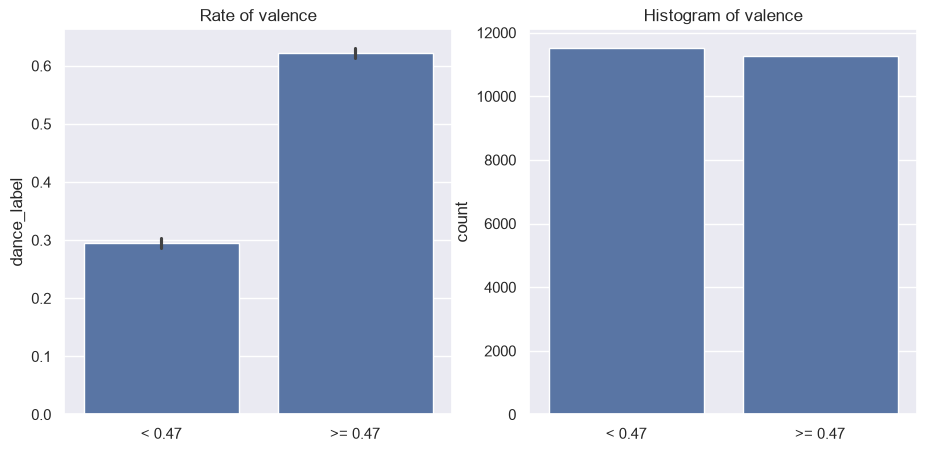

In [50]:
#Keep cell

import seaborn as sns

mean_valence = np.where(test_set['valence'] < 0.47, '< 0.47', '>= 0.47')

fig,axs = plt.subplots(1,2, figsize=(11,5))
sns.barplot(data=test_set, y="dance_label", x=mean_valence, ax=axs[0]).set(title="Rate of valence")
sns.countplot(data=test_set, x=mean_valence, ax=axs[1]).set(title="Histogram of valence")

The plot visually explores the relationship between a `valence` feature split at 0.47 and `dance_label` in the test dataset. The bar plot on the left shows the proportion of 'High Danceability' songs within each `valence` category, while the count plot on the right shows the distribution of songs across these `valence` categories. On the left, we see that the rate of 'High Danceability' differs fairly strongly between songs with low `valence` (< 0.47) and high `valence` (>= 0.47) in the test set. On the right, the number of songs in the test dataset is shown that fall into each `valence` category ('< 0.47' and '>= 0.47'). It shows that they are evenly distributed. This helps understand if `valence` (and the split at 0.47) is a good predictor for danceability and how many songs fall into each category. This is a step towards understanding potential split points for a decision tree. Even though the rate of 'High Danceability' differs between the two groups, we suspect that splitting `valence` at 0.47 is not the best possible split. Let's investigate further ...

We now create a very simple model, which simply says that music of `valence` less than 0.47 is good (which corresponds to 1 in our case), while the ones above that value are bad. To do so, we evaluate with our `test_set` to see how accurate this approach turns out to be.

In [51]:
#Keep cell
preds = test_set['valence'].values < 0.47
preds = preds.astype(int)
preds

array([1, 1, 1, ..., 0, 1, 0], shape=(22800,))

Let's check this with yet another metric so that we learn a little more. Mean absolute error (MAE; https://en.wikipedia.org/wiki/Mean_absolute_error) measures the absolute error difference between the prediction and the actual value. In our case, the absolute error would be 0 if the predicted value corresponds to the actual one and 1 otherwise. sklearn calculates it with the function `mean_absolute_error` from `sklearn.metrics`.

Complete the next cell.

In [57]:
#Complete cell

from sklearn.metrics import mean_absolute_error
mean_absolute_error(test_set['dance_label'], preds)

0.664298245614035

In [56]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q9.hint()
#q9.solution()

<IPython.core.display.Javascript object>

<span style="color:#3366cc">Hint:</span> Import and use mean_absolute_error from sklearn.metrics to evaluate model performance. MAE measures average absolute difference between predictions and actual values. Syntax: mean_absolute_error(actual_values, predicted_values)

I am getting something like 0.66, which is not great: a single, simple split makes many errors. A decision tree does better because it searches for the *best* split, and then keeps splitting the groups it has made.

### Optional: how a tree finds the best split

This section shows what a decision tree does inside. **There are no exercises here**: all cells are complete. Run them and read along, or skip to *Sklearn's decision trees* below.

First, the same split on another column, `liveness`.

In [58]:
#Keep cell
mean_liveness = np.mean(train_set['liveness'])
preds = (test_set['liveness'].values < mean_liveness).astype(int)
print('Preds: ', preds)
print('Mean absolute error: ', mean_absolute_error(test_set['dance_label'], preds))

Preds:  [1 0 1 ... 0 0 1]
Mean absolute error:  0.4657017543859649


This looks better. Why?

Let's speed things up and try several columns and splits at the same time.

We create a function `score_` to test how a split on a column affects the overall model we want to build. As we want to move slowly towards decision trees, we do not simply split on a column's average but on a measure called impurity (https://en.wikipedia.org/wiki/Decision_tree_learning). Impurity indicates how the two groups that a split creates are similar or dissimilar from each other. The smaller the impurity, the better the split. We call these groups `left_group` and `right_group`.

How do we measure group similarity? Similarity is often the big question in data analytics. In this case, we take the standard deviation of the target, which is `dance_label`. If you don't remember standard deviation from school, it is basically a measure of the amount of variation of values (https://en.wikipedia.org/wiki/Standard_deviation). Can you see where in the code below?

Standard deviation or `std()` is thus a measure of the spread of two groups. If it is higher, the groups are more dissimilar. Then, we multiply by the number of data items in the groups, because a bigger group has more impact.

We do this twice for both the left and the right split.

In [59]:
#Keep cell
#The aim of score_ is to use a particular split point in a target variable to create similar groups according to the target column.

def score_(column_values, target_values, split_point):
    left_group_score = 0
    right_group_score = 0

    left_mask = column_values < split_point
    left_count = left_mask.sum()
    if left_count <= 1:
        left_group_score = 0
    else:
        left_group_score = target_values[left_mask].std() * left_count

    right_mask = column_values >= split_point
    right_count = right_mask.sum()
    if right_count <= 1:
        right_group_score = 0
    else:
        right_group_score = target_values[right_mask].std() * right_count

    return (left_group_score + right_group_score) / len(target_values) if len(target_values) > 0 else 0



Run `score_` with mean `valence` in the cell below. Observe how `score_` operates on `train_set` to find the best splits and then is tested with `test_set`. The splits are learned from training data and `test_set` is used only for evaluation.

In [60]:
#Keep cell
mean_valence = np.mean(train_set['valence'])
print(score_(test_set['valence'].values, test_set['dance_label'].values, mean_valence))

0.47028525302390556


The same for `acousticness`:

In [61]:
#Keep cell

mean_acousticness = np.mean(train_set['acousticness'])
print(score_(test_set['acousticness'].values, test_set['dance_label'].values, mean_acousticness))

0.4961410009002029


The scores are close, but mean valence seems to be a better split because the score is lower.

But why split at the mean? Let's use the computer to find the best split point for a column automatically. To find the best splits, we first need a number of unique split points. Let's try this for the first column `valence`. The code uses the `unique()` function from Pandas and then sorts the values with `sorted()`. At the end, we print out only the first 15 `unq` values.

In [62]:
#Keep cell
col_ = 'valence'
unq = train_set[col_].unique()
[float(u) for u in sorted(unq)[:15]]

[0.0,
 1e-05,
 0.000322,
 0.000378,
 0.000667,
 0.000673,
 0.000755,
 0.000885,
 0.00104,
 0.00115,
 0.00119,
 0.00122,
 0.00142,
 0.00149,
 0.00154]

Let's score with these values. Run the cell below and check out what `argmin()` does in the documentation. It looks for the smallest value and returns its index in a list.

In [63]:
#Keep cell
scores = np.array([score_(train_set[col_], train_set['dance_label'], o) for o in unq if not np.isnan(o)])
print(unq[scores.argmin()])

0.427


For this column, 0.427 seems to be the best cut-off for the splits.

A typical move in data analysis with Jupyter notebooks is to bring various cells together into one function to run them together. Let's define `min_column` using the previous two cells.

Run the cell below.

In [64]:
#Keep cell

def min_column(df, col_):
    df = df.sample(frac=0.1, random_state=4711) # For demonstration purposes, we take a sample of train_set to find the min column
    unq = df[col_].dropna().unique()
    s = np.array([score_(df[col_], df['dance_label'], o) for o in unq if not np.isnan(o)])
    idx = s.argmin()
    return (col_, float(unq[idx]), float(s[idx]))

min_column(train_set, 'valence')

('valence', 0.516, 0.47198810458599455)

For all columns, we print out the name of the column, the split value and the impurity - ignoring the last column, which is `dance_label`, with the index -1.

Run the next cell.

In [65]:
#Keep cell

for w in list(train_set.columns[:-1]):
    print(min_column(train_set, w))

('valence', 0.516, 0.47198810458599455)
('liveness', 0.115, 0.49542334176295605)
('tempo', 146.148, 0.48883025896628013)
('acousticness', 0.000546, 0.486225598574295)
('energy', 0.928, 0.4886468754114062)
('speechiness', 0.0477, 0.4946339211768792)
('instrumentalness', 4.88e-05, 0.4964795504995114)
('loudness', -16.631, 0.49042656638693877)
('popularity', 16.0, 0.49724318757711017)


According to my output, `valence <= 0.516` is the best split we can use. Why? Because it has the smallest value of impurity. (This differs from the 0.427 we found above, because `min_column` only uses a 10% sample of `train_set`.)

We have (almost) re-invented the OneR machine-learning algorithm (https://rasbt.github.io/mlxtend/user_guide/classifier/OneRClassifier/ or https://christophm.github.io/interpretable-ml-book/rules.html). It's not very popular anymore but was very much used in the 1990s. It often provides a great baseline to compare more advanced models with. We can think of OneR and what we have done as a one-rule tree.

How about we add another split after the first one with `valence`? We first pick the best split for `valence` and then find the best split for each of the two subgroups this split produces. To this end, we just have to repeat the previous step for each of the two groups based on a split of `valence <= 0.516`.

Let's do this split first by running the next cell.

In [66]:
#Keep cell
left_split_valence = train_set.loc[train_set['valence'] <= 0.516, :]
right_split_valence = train_set.loc[train_set['valence'] > 0.516, :]

Let's repeat the previous step first for `left_split_valence`.
To this end, we have to remove both the 'valence' and the 'dance_label', as we do not want to split over valence again and do not need the target column.

Run the cell below.

In [67]:
#Keep cell
left_split_valence_columns = [c for c in left_split_valence.columns if c not in ['valence', 'dance_label']]
for w in left_split_valence_columns:
    print(min_column(left_split_valence, w))

('liveness', 0.684, 0.46030411887123707)
('tempo', 134.064, 0.4519317358182059)
('acousticness', 0.00054, 0.4543070205540208)
('energy', 0.936, 0.45385498992535295)
('speechiness', 0.0439, 0.4569138825725627)
('instrumentalness', 0.968, 0.460696292290504)
('loudness', -20.66, 0.45309155941107193)
('popularity', 40.0, 0.46047629786889194)


The best next split uses `tempo`.

Now the same for `right_split_valence`. Run the next cell.

In [68]:
#Keep cell
right_split_valence_columns = [c for c in right_split_valence.columns if c not in ['valence', 'dance_label']]
for w in right_split_valence_columns:
    print(min_column(right_split_valence, w))

('liveness', 0.187, 0.4728465054460728)
('tempo', 136.129, 0.46316699397544575)
('acousticness', 0.00429, 0.47036109378054264)
('energy', 0.886, 0.47219219715572885)
('speechiness', 0.122, 0.4740377645078241)
('instrumentalness', 0.95, 0.47844270610272094)
('loudness', -15.348, 0.4783880860138319)
('popularity', 18.0, 0.47606081533219763)


The best next split for the right group would be `tempo` too. We could continue this for the four subgroups we have now, and again and again: that is a decision tree. The model starts with the valence of the songs and adds splits, or rules, until no better splits are left.

### Sklearn's decision trees

We do not want to do all this by hand, so we let sklearn's `DecisionTreeClassifier` do it for us. For sklearn, we need to create `X_train`, `y_train`, etc.

Complete the next cell.

In [69]:
#Complete cell

X_train = train_set.loc[:, train_set.columns != 'dance_label'].values
y_train = train_set['dance_label'].values

X_test = test_set.loc[:, test_set.columns != 'dance_label'].values
y_test = test_set['dance_label'].values

In [70]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q15.check()
#q15.hint()
#q15.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

Complete the code below to set up the model.

> **Hint:** Tip: `max_leaf_nodes=4` limits the size of the tree.

In [72]:
#Complete cell
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_leaf_nodes=4, random_state=4711).fit(X_train, y_train)

In [73]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q16.check()
#q16.hint()
#q16.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

Draw the resulting tree for `X_train`. Before running this cell you might have to install graphviz on your system - if you are not on Colab: https://www.graphviz.org/download/.

Run the cell below.

[Text(0.5, 0.8333333333333334, 'valence <= 0.505\ngini = 0.496\nsamples = 100.0%\nvalue = [0.544, 0.456]'),
 Text(0.25, 0.5, 'tempo <= 135.17\ngini = 0.427\nsamples = 55.0%\nvalue = [0.691, 0.309]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.463\nsamples = 38.3%\nvalue = [0.636, 0.364]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.297\nsamples = 16.7%\nvalue = [0.818, 0.182]'),
 Text(0.75, 0.5, 'tempo <= 144.128\ngini = 0.462\nsamples = 45.0%\nvalue = [0.363, 0.637]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.42\nsamples = 34.7%\nvalue = [0.3, 0.7]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.489\nsamples = 10.3%\nvalue = [0.575, 0.425]')]

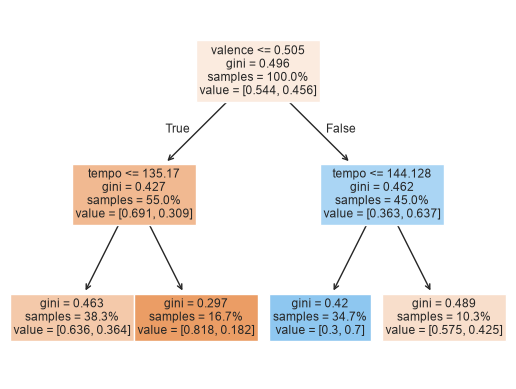

In [74]:
#Keep cell

from sklearn.tree import plot_tree

plot_tree(model, feature_names = train_set.columns, proportion=True, filled=True)

> **Background: gini** (optional reading)
>
> Gini measures how mixed a group is. It is the probability that two rows picked at random from the group have a different label. 0 means the group is pure (all songs danceable, or none); 0.5 is the maximum, for a 50/50 mix. It is explained in more detail at https://goto4711.github.io/decision-tree-visualisation/. A version of the function as sklearn uses it:
> ```
> def gini(counts):
>     total = sum(counts)
>     impurity = 1.0
>     for c in counts:
>         p = c / total
>         impurity -= p * p
>     return impurity
> ```
> `counts` holds the number of rows of each class at a node. At the root node, 54.4% of the training songs are not danceable and 45.6% are, so gini is 1 - 0.544² - 0.456², about 0.496, as the drawing shows.
>
> Gini is often the default for splitting a decision tree, and you can use it out of the box. But you should always know a little about such measures, at least whether a higher or a lower value means a better split.

The tree first splits on `valence` and then on `tempo`: the same features that the optional section found by hand, at slightly different values (`valence <= 0.505` instead of 0.516), because the optional section used a 10% sample and a simpler measure of impurity.

Each node shows how many 'samples' (rows of the training data) end up there, and as 'value' the proportions of these samples with low and high danceability. 'gini' measures how mixed a node still is: 0 means pure (only low or only high danceability), 0.5 a 50/50 mix. sklearn picks the splits that make the nodes as pure as possible. It is explained in more detail at https://goto4711.github.io/decision-tree-visualisation/.

Let us see how well the tree predicts. Complete the cell below.

In [78]:
#Complete cell

preds = model.predict(X_test)
mean_absolute_error(y_test, preds)

0.31298245614035086

In [77]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q17.check()
q17.hint()
#q17.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

<IPython.core.display.Javascript object>

<span style="color:#3366cc">Hint:</span> Use the trained model to make predictions on the test set with .predict(). Then calculate the mean absolute error to evaluate performance. This measures how often the model's predictions differ from actual labels.

It is already much better than our single split on valence above.

We can do even better if we make the decision tree deeper. You might have noticed that our original sklearn decision tree had a parameter of `max_leaf_nodes=4`, which says we only want 4 leaf nodes. With `min_samples_leaf=200`, we can increase the size of the tree. This is the minimum number of samples required to be at a leaf node. Check out https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html.

Run the cell below. This takes a while ...

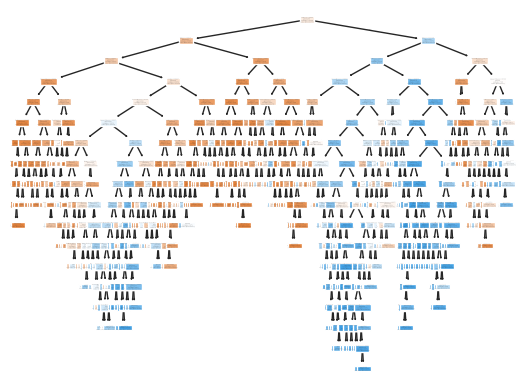

In [79]:
#Keep cell
model_2 = DecisionTreeClassifier(min_samples_leaf=200, random_state=4711)
model_2.fit(X_train, y_train)

_ = plot_tree(model_2, feature_names = train_set.columns, proportion=True, filled=True)

This looks impressively complex. Let us check out how the model does.

Complete the next cell to run an evaluation.

In [81]:
#Complete cell
preds = model_2.predict(X_test)
mean_absolute_error(y_test, preds)

0.23328947368421052

In [82]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q18.check()
#q18.hint()
#q18.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

A bit better, but does this justify the complexity? This is a decision we have to make.

### Random Forest

We do not really want to make the decision trees much more complex than what we have just seen.

So, how can we go further from here? One idea was developed by Leo Breiman, who suggested creating lots of trees and taking the average of their predictions (Breiman, L. Random Forests. Machine Learning 45, 5-32 (2001). https://doi.org/10.1023/A:1010933404324).

Taking the average like this is also known as 'bagging'. For this so-called 'ensemble' of decision trees (https://en.wikipedia.org/wiki/Ensemble_learning), we have a particular name and call it a random forest.

The following will create a decision tree from a random subset of the training data, repeat this for 10 trees, average their predictions and compute the mean absolute error of this average prediction.

Run the two cells below.

In [83]:
#Keep cell
from numpy import random

X_train = train_set.loc[:, train_set.columns != 'dance_label'].values
y_train = train_set['dance_label'].values

X_test = test_set.loc[:, test_set.columns != 'dance_label'].values
y_test = test_set['dance_label'].values

def get_tree_model(prop=0.75, seed=None):
    n = len(y_train)
    #ids are random choice of numbers; a fixed seed makes each tree repeatable
    rng = random.default_rng(seed)
    ids = rng.choice(n, int(n*prop))
    return DecisionTreeClassifier(min_samples_leaf=5, random_state=seed).fit(X_train[ids], y_train[ids])

In [84]:
#Keep cell

#Get 10 decision tree models
tree_models = []
for t in range(10): #create 10 trees
    tree_models.append(get_tree_model(seed=4711 + t))

all_probs = []
for tm in tree_models:
    all_probs.append(tm.predict(X_test))

#Calculate the average prediction for each row by taking the mean
avg_probs = np.array(all_probs).mean(0)

mean_absolute_error(y_test, avg_probs)

0.22991666666666669

This is better than my decision tree, which we should expect. We are on a good track.

What we have just created is done better with sklearn's `RandomForestClassifier`, which follows the same principles but better. `RandomForestClassifier` offers some extra tricks such as picking a random subset of columns for each split.

Let us create everything in one go with sklearn. Complete the following code by using the sklearn documentation: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html.

In [85]:
#Complete cell
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(10, min_samples_leaf=5, random_state=4711)
rf.fit(X_train, y_train);
mean_absolute_error(y_test, rf.predict(X_test))

0.1600877192982456

In [86]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q19.check()
#q19.hint()
#q19.solution()

<IPython.core.display.Javascript object>

<span style="color:#33cc33">Correct</span>

This is significantly better and better than my neural net from the lecture. As you can see, it is hard to beat an algorithm from 2001 for structured data analysis.

One more test.

In [87]:
# Run this cell to test your code...
cond_ = pd.Series(rf.feature_importances_, index=train_set.columns[:-1]).sort_values()[-1:].index.values[0]=='valence'
assert cond_, f'Test failed'
print('All tests passed!')

All tests passed!


Another nice aspect of random forests is they can tell us which inputs are most important for the predictions, using `feature_importances_`.

Let's try to re-implement the example https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html. We ignore the standard deviation discussion.

Complete the cell below: sort the importances from the most to the least important.

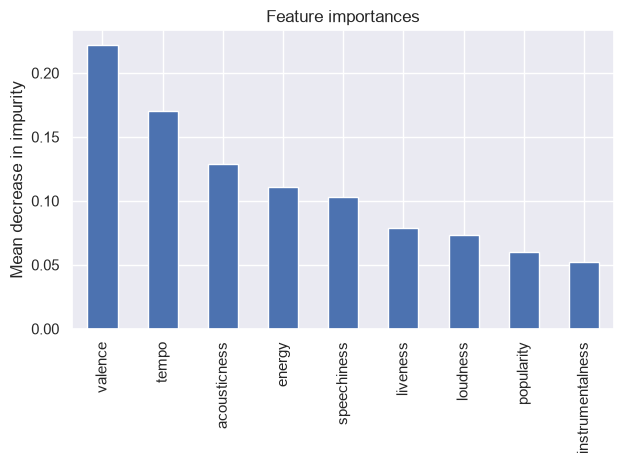

In [90]:
#Complete cell
import pandas as pd

forest_importances = pd.Series(rf.feature_importances_, index=train_set.columns[:-1])

fig, ax = plt.subplots()
forest_importances.sort_values(ascending=False).plot.bar(ax=ax) #Sorting as well ...
ax.set_title("Feature importances")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [ ]:
#Keep cell. To see a hint or the solution, remove the # in front of that line.
q20.hint()
#q20.solution()

Valence, tempo and acousticness are the three most important features.

Valence is clearly dominating though. Let's have a quick look at what a maximum combination of `valence` and `danceability` is. The next video is the song in the dataset with the maximum product of `valence` and `danceability`.

In [91]:
#Keep cell
#Multiplying valence and danceability and then selecting the max of product  gives us ... Oh well ...

combined_example = "-RSIIu0WWcM"
display_youtube(combined_example, video_title="Example of most danceable music with highest valence")

> **Who decided?** The forest learned which features matter, but people decided what it could learn from: someone collected these 114,000 songs, Spotify computed "danceability" and "valence" from the audio with its own models, we turned danceability into a label by cutting at 0.6, and we chose the nine features, the 80/20 split and the size of the trees. A different threshold would give a different "danceable" song.

### Optional: check an agent

Gemini can also do everything we have done. Ask Gemini to "Create training and test dataset for `music_df` with a test split of 0.2. Then, make a random forest model and evaluate it with the mean absolute error. Finally, visualise the feature importance." Does it make the same decisions as we did? Which ones does it make without telling you?

Mean absolute error: 0.13206140350877194


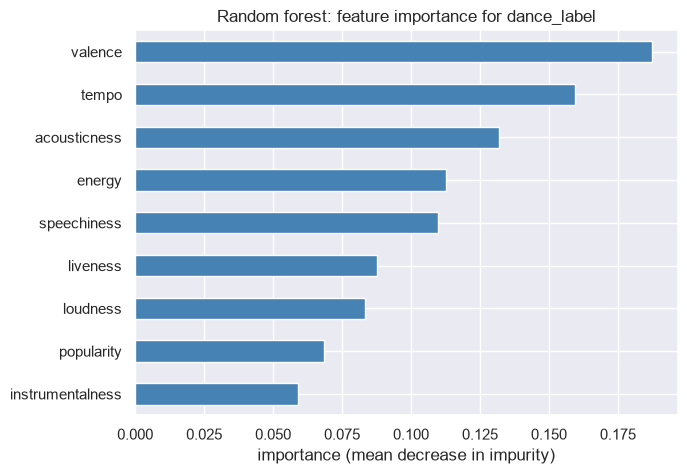

In [92]:
# prompt: Create training and test dataset for music_df with a test split of 0.2. Then, make a random forest model and evaluate it with the mean absolute error. Finally, visualise the feature importance.

#Here’s code for that cell. I tested it on the Spotify data with your Python 3.11, and it runs in about 4 seconds.

# prompt: Create training and test dataset for music_df with a test split of 0.2. Then, make a random forest model and evaluate it with the mean absolute error. Finally, visualise the feature importance.
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error

# features = every column except the label; target = dance_label
X_a = music_df.drop(columns='dance_label')
y_a = music_df['dance_label']

# 80% training, 20% test
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a, y_a, test_size=0.2, random_state=42)

# random forest with sklearn's default settings (100 trees)
rf_agent = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_agent.fit(X_train_a, y_train_a)

print('Mean absolute error:', mean_absolute_error(y_test_a, rf_agent.predict(X_test_a)))

# feature importance, largest bar on top
importances = pd.Series(rf_agent.feature_importances_, index=X_a.columns).sort_values()
plt.figure(figsize=(7, 5))
importances.plot(kind='barh', color='steelblue')
plt.title('Random forest: feature importance for dance_label')
plt.xlabel('importance (mean decrease in impurity)')
plt.ylabel('')
plt.show()

# I gave the variables an _a suffix (X_train_a and so on), so this cell doesn’t overwrite X_train, y_test and the others from your own work above.

# Result: the mean absolute error is about 0.132, so the forest gets roughly 87% of the test songs right. Valence matters most, followed by tempo and acousticness; instrumentalness and popularity matter least.

# Decisions made without the prompt saying so, which is what the workshop question asks you to look for:

# Target: I assumed dance_label is what to predict, and that all other columns are features. The prompt never says this.
# Classifier vs. regressor: I chose RandomForestClassifier because the label is 0/1. An agent could just as well pick RandomForestRegressor, which changes what the MAE means.
# random_state=42: this fixes which songs end up in training and test. The notebook used 4711 for the forest, so the numbers differ slightly from yours.
# Settings: I used 100 trees and the default leaf size. The notebook used 10 trees with min_samples_leaf=5, so the two models aren’t the same.
# What importance means: sklearn’s built-in importance measures how much each feature splits the training data. That isn’t the same as how much it causes danceability, and it tends to favour features with many distinct values, like tempo.
# What the model never sees: danceability itself was used to make the label and then left out. Genre, artist and key were never features. Those choices were made in the notebook’s data-preparation cell, not by the agent, but the prompt hides them.

> **Read more:** Impressive! Why not practice more now at https://www.w3schools.com/python/python_ml_decision_tree.asp?

By understanding the principles of decision trees and random forests, you have a great option to analyse most structured data. I am proud of you.

That's it for machine learning 101! That was not too hard, was it?

> **Important:** Run the next cell to make an HTML file of your notebook for Canvas. It downloads automatically. First save the notebook (Ctrl+S, or ⌘+S on a Mac): the cell reads the notebook as it is on your screen, and if that does not work, it looks for your saved copy in Google Drive. If you are asked to allow access to your Google Drive, please confirm. Before you hand it in, open the HTML file and check that all your results are there. Its first line says when and how it was made.

In [93]:
#Keep cell
# Makes an HTML file of this notebook (local version for VS Code / Jupyter, no Google Drive needed)
# FIRST save the notebook (⌘+S): the HTML is made from the saved file, not from what is on screen
import re
import nbformat
from nbconvert import HTMLExporter
from datetime import datetime

notebook_file = 'Week3_Workshop.ipynb'
html_file = 'Week3_Workshop.html'

nb = nbformat.read(notebook_file, as_version=4)
body, _ = HTMLExporter().from_notebook_node(nb)

stamp = f'<p>Made on {datetime.now():%Y-%m-%d %H:%M} from {notebook_file} with nbconvert</p>'
body = re.sub(r'(<body[^>]*>)', r'\1' + stamp, body, count=1)   # put the stamp at the top of the page

with open(html_file, 'w', encoding='utf-8') as f:
    f.write(body)
print('Saved', html_file, '- open it and check that all your results are there before handing it in')

Saved Week3_Workshop.html - open it and check that all your results are there before handing it in
